In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#get the dataset
columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv('/content/iris.data', header=None, names=columns)
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


In [159]:
#values needed
df = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
original_data = df.copy()
mean = df.mean()
std = df.std()

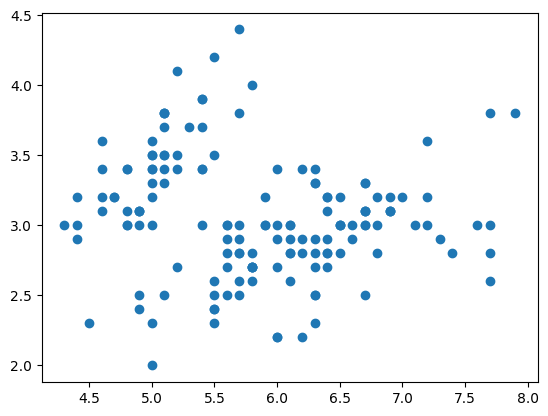

In [160]:
ax = plt.axes()
ax.scatter(df["sepal_length"], df["sepal_width"])
plt.show()

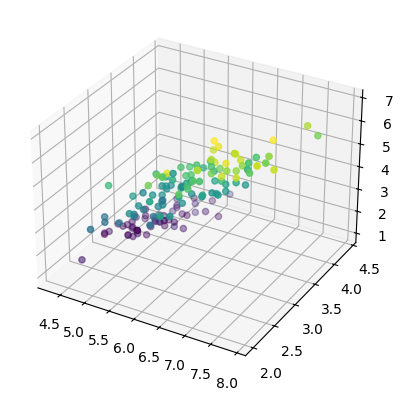

In [161]:
ax = plt.axes(projection='3d')
ax.scatter(df["sepal_length"], df["sepal_width"], df["petal_length"], c = df["petal_width"])
plt.show()

In [162]:
#center it (subtract each column's mean)
df = df.apply(
    lambda x: x - x.mean()
)

print(df)

     sepal_length  sepal_width  petal_length  petal_width
0       -0.743333        0.446     -2.358667    -0.998667
1       -0.943333       -0.054     -2.358667    -0.998667
2       -1.143333        0.146     -2.458667    -0.998667
3       -1.243333        0.046     -2.258667    -0.998667
4       -0.843333        0.546     -2.358667    -0.998667
..            ...          ...           ...          ...
145      0.856667       -0.054      1.441333     1.101333
146      0.456667       -0.554      1.241333     0.701333
147      0.656667       -0.054      1.441333     0.801333
148      0.356667        0.346      1.641333     1.101333
149      0.056667       -0.054      1.341333     0.601333

[150 rows x 4 columns]


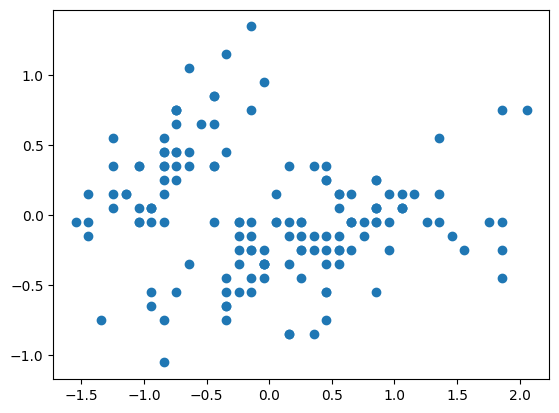

In [163]:
ax = plt.axes()
ax.scatter(df["sepal_length"], df["sepal_width"])
plt.show()

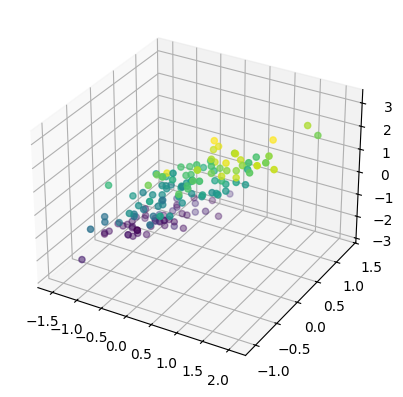

In [164]:
ax = plt.axes(projection='3d')
ax.scatter(df["sepal_length"], df["sepal_width"], df["petal_length"], c = df["petal_width"])
plt.show()

In [165]:
#find the covariance matrix
df_normalized = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].apply(
    lambda x: x / x.std()
)

col_num = df_normalized.shape[0]
sample_covariance_matrix = 1/(col_num-1) * (df_normalized.T @ df_normalized)

print(sample_covariance_matrix.head())

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.109369      0.871754     0.817954
sepal_width      -0.109369     1.000000     -0.420516    -0.356544
petal_length      0.871754    -0.420516      1.000000     0.962757
petal_width       0.817954    -0.356544      0.962757     1.000000


In [166]:
#find the eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(sample_covariance_matrix)

In [167]:
#sort them by biggest eigenvalue first (biggest = maximum variance, next = perpendicular variance)
eigenvalues = eigenvalues[::-1]
eigenvectors = eigenvectors[:, ::-1]

biggest = eigenvalues[0]
next = eigenvalues[1]

In [168]:
total_eigenvalue = eigenvalues.sum()
EXPECTED_VARIANCE = 95

currentsum = 0
for i in range(len(eigenvalues)):
  currentsum += eigenvalues[i]
  cev = (currentsum / total_eigenvalue) * 100
  if cev >= EXPECTED_VARIANCE:
    eigenvalues = eigenvalues[:i+1]
    eigenvectors = eigenvectors[:, :i+1]
    break


In [169]:
#can rotate the centered data onto the kept eigenvectors
centered_data = df_normalized @ eigenvectors

In [170]:
print(centered_data.head())

          0         1
0  2.256981  0.504015
1  2.079459 -0.653216
2  2.360044 -0.317414
3  2.296504 -0.573447
4  2.380802  0.672514


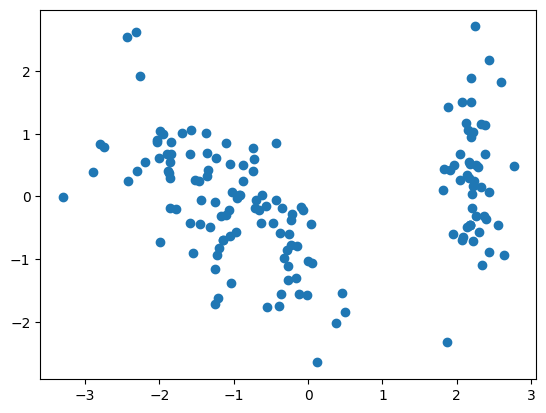

In [171]:
ax = plt.axes()
ax.scatter(centered_data[0], centered_data[1])
plt.show()

In [172]:
#can reconstruct it back
reconstructed_data = centered_data @ eigenvectors.T #original dimensions
reconstructed_data.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

print(reconstructed_data.head())

reconstructed_data = reconstructed_data * std + mean

print(reconstructed_data.head())

   sepal_length  sepal_width  petal_length  petal_width
0     -0.991328     1.060882     -1.301247    -1.243603
1     -1.329455    -0.056953     -1.222473    -1.218896
2     -1.350999     0.327745     -1.378481    -1.355631
3     -1.413133     0.074038     -1.346949    -1.336440
4     -0.993274     1.249446     -1.369664    -1.302615
   sepal_length  sepal_width  petal_length  petal_width
0      5.022448     3.513992      1.462720     0.249598
1      4.742457     3.029306      1.601710     0.268453
2      4.724617     3.196108      1.326447     0.164102
3      4.673166     3.086103      1.382083     0.178748
4      5.020837     3.595753      1.342004     0.204562


In [173]:
#mse error
print(np.mean(
    (original_data - reconstructed_data) ** 2
))


0.035568259919525454
